# Лабораторная работа №3
**Тема:** Визуализация данных (Pandas, Matplotlib, Seaborn)
**Выполнил:** Мельников А.И.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

df = pd.read_csv('StudentsPerformance.csv')
display(df.head())
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


,count,mean,std,min,50%,max
math score,1000.0,66.089,15.163080,0.0,66.0,100.0
reading score,1000.0,69.169,14.600192,17.0,70.0,100.0
writing score,1000.0,68.054,15.195657,10.0,69.0,100.0


## 1. Визуализация средствами Pandas
1.1 Столбчатая диаграмма уровня образования родителей (`parental level of education`).
1.2 Круговая диаграмма этнических групп (`race/ethnicity`).
1.3 Гистограммы для всех числовых столбцов одним вызовом функции.


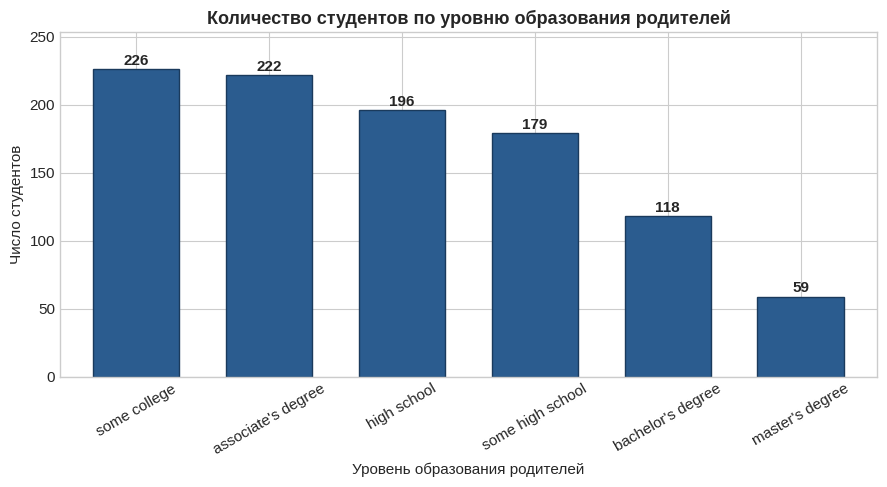

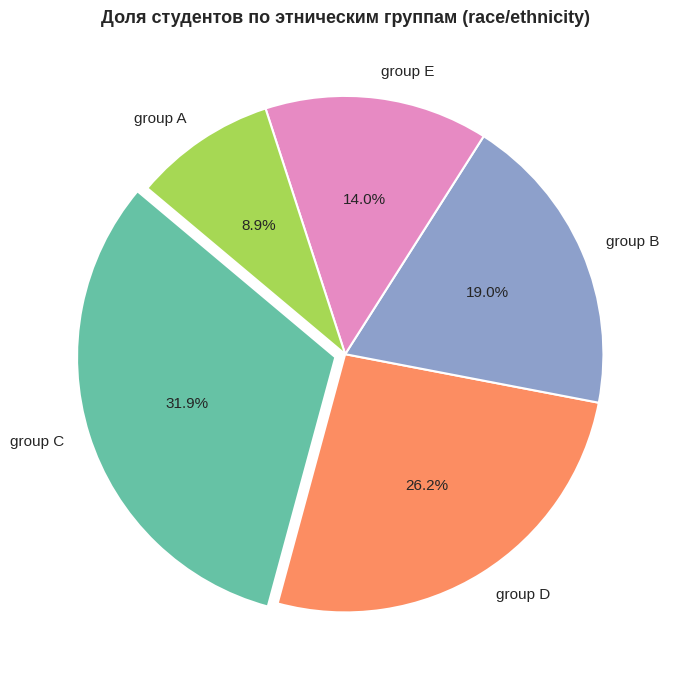

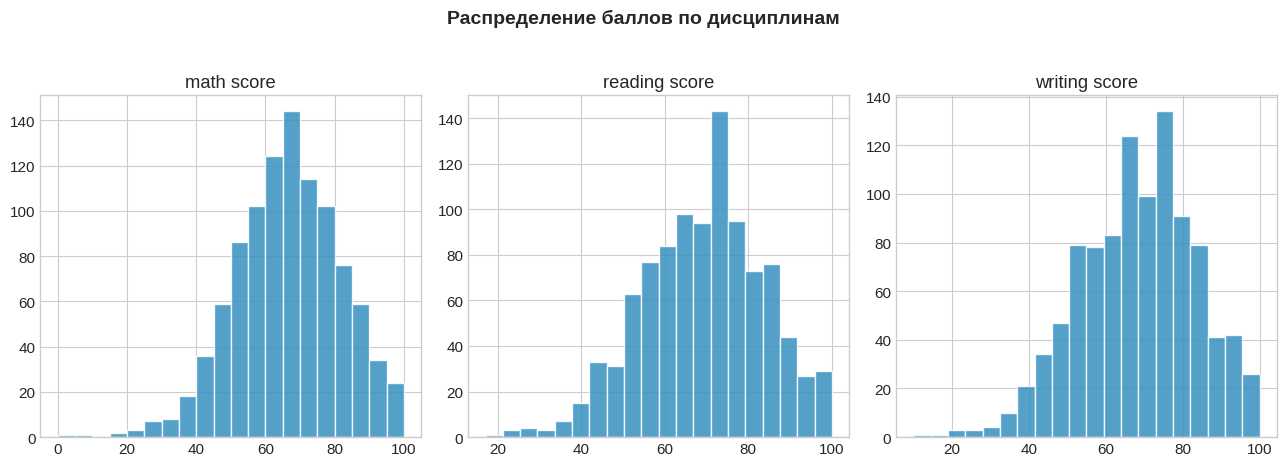

In [6]:
# 1.1 Столбчатая диаграмма
fig, ax = plt.subplots(figsize=(9, 5))
edu_counts = df['parental level of education'].value_counts()
edu_counts.plot(kind='bar', ax=ax, color='#2b5c8f', edgecolor='#1a3a5c', width=0.65)
ax.set_title('Количество студентов по уровню образования родителей', fontsize=13, fontweight='bold')
ax.set_xlabel('Уровень образования родителей')
ax.set_ylabel('Число студентов')
ax.tick_params(axis='x', rotation=30)
for i, val in enumerate(edu_counts.values):
    ax.text(i, val + 3, str(val), ha='center', fontweight='bold')
ax.set_ylim(0, max(edu_counts.values) * 1.12)
plt.tight_layout()
plt.show()

# 1.2 Круговая диаграмма
fig, ax = plt.subplots(figsize=(7, 7))
race_counts = df['race/ethnicity'].value_counts()
race_counts.plot(
    kind='pie', ax=ax, autopct='%1.1f%%', startangle=140,
    colors=sns.color_palette('Set2', len(race_counts)),
    explode=[0.04 if i == 0 else 0 for i in range(len(race_counts))],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
ax.set_title('Доля студентов по этническим группам (race/ethnicity)', fontsize=13, fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

# 1.3 Гистограммы одним вызовом
df.hist(figsize=(13, 4.5), bins=20, layout=(1, 3), color='#3690c0', edgecolor='white', alpha=0.85)
plt.suptitle('Распределение баллов по дисциплинам', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 2. Набор графиков в Matplotlib (Subplots 3x2)
Построение сетки из 6 графиков (`X=1..6`) и проверка наличия выбросов по математике (`math score`).


Нижняя граница нормы: 27.0 баллов. Выбросы (8 шт.): [0, 8, 18, 19, 22, 23, 24, 26]



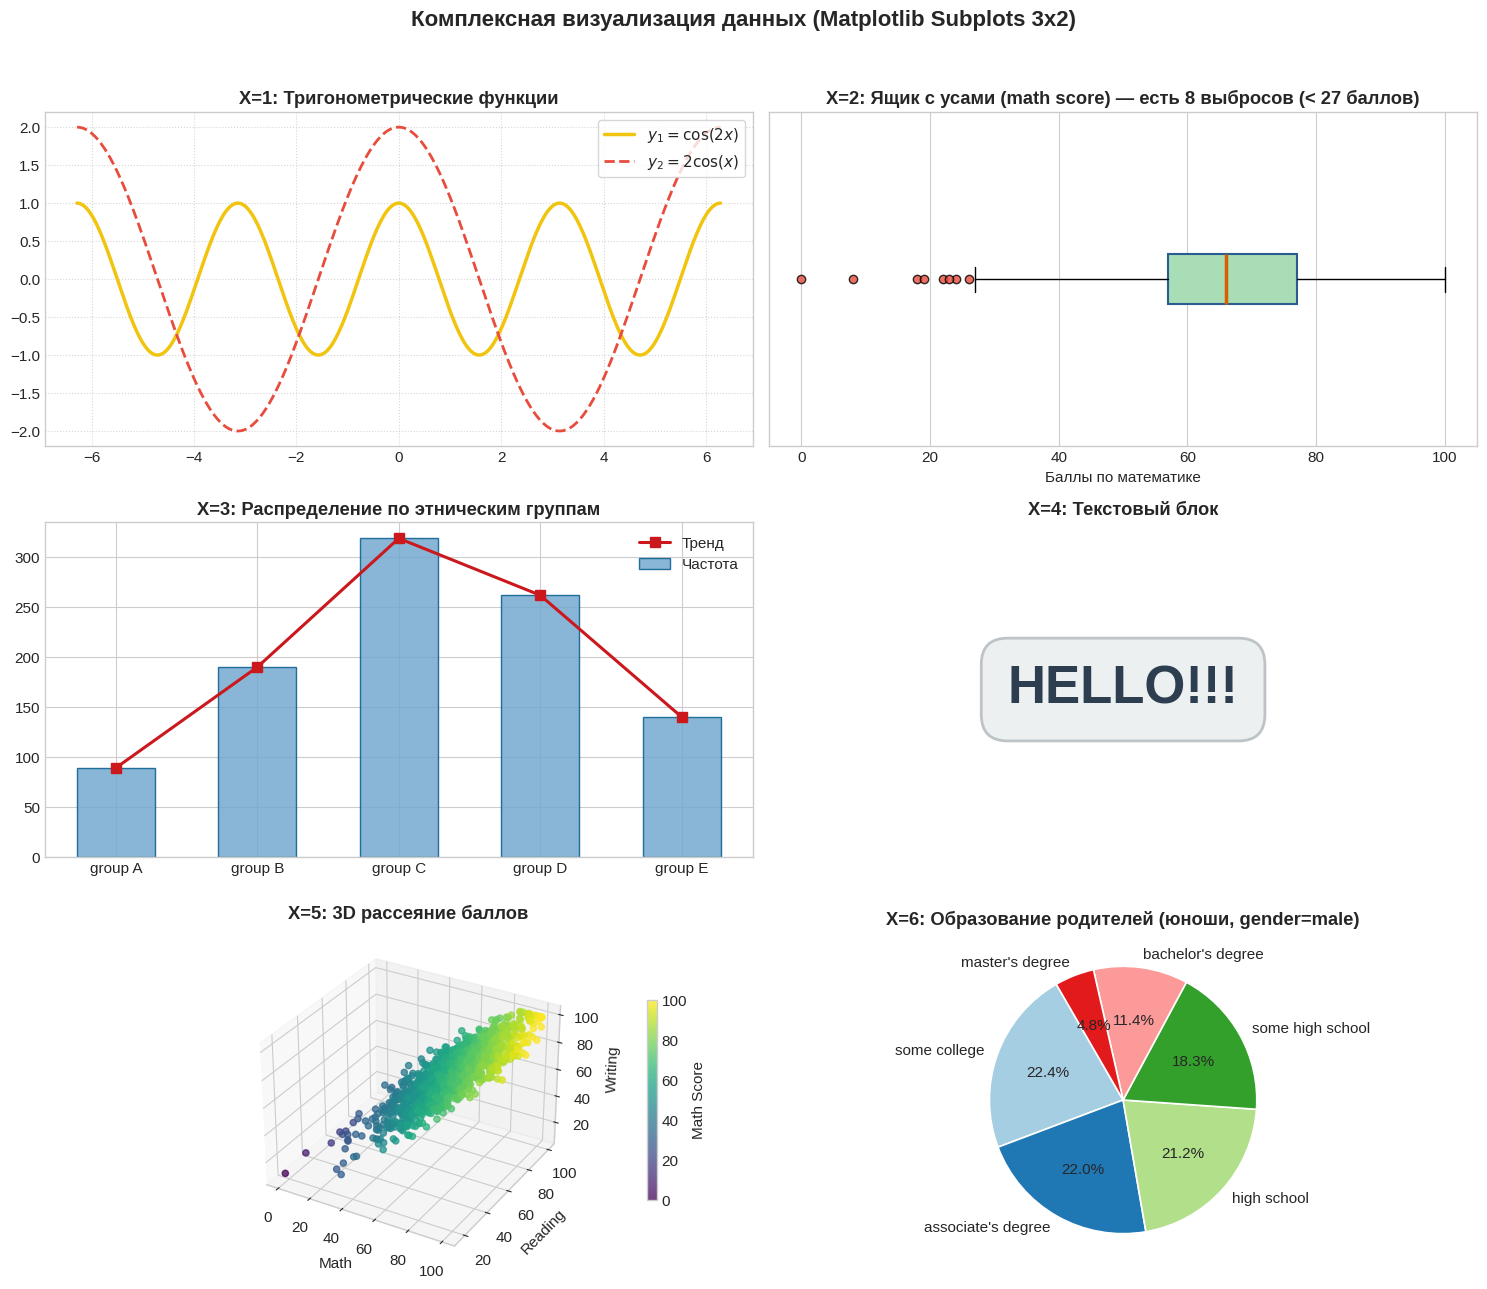

In [7]:
# Проверка выбросов для math score по методу межквартильного размаха (IQR)
q25, q75 = np.percentile(df['math score'], [25, 75])
iqr = q75 - q25
lower_limit = q25 - 1.5 * iqr
outliers = df.loc[df['math score'] < lower_limit, 'math score'].sort_values().tolist()
print(f"Нижняя граница нормы: {lower_limit} баллов. Выбросы ({len(outliers)} шт.): {outliers}\n")

fig = plt.figure(figsize=(15, 13))
fig.suptitle('Комплексная визуализация данных (Matplotlib Subplots 3x2)', fontsize=16, fontweight='bold', y=0.98)

# X = 1: y1 = cos(2x) и y2 = 2cos(x)
ax1 = plt.subplot(321)
x_vals = np.linspace(-2 * np.pi, 2 * np.pi, 400)
ax1.plot(x_vals, np.cos(2 * x_vals), color='#f1c40f', linewidth=2.5, label=r'$y_1 = \cos(2x)$')
ax1.plot(x_vals, 2 * np.cos(x_vals), color='#e74c3c', linewidth=2, linestyle='--', label=r'$y_2 = 2\cos(x)$')
ax1.set_title('X=1: Тригонометрические функции', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.8)
ax1.legend(loc='upper right', frameon=True)

# X = 2: Ящик с усами для math score
ax2 = plt.subplot(322)
ax2.boxplot(
    df['math score'], vert=False, patch_artist=True,
    boxprops=dict(facecolor='#a8ddb5', edgecolor='#2b5c8f', linewidth=1.5),
    medianprops=dict(color='#d95f02', linewidth=2.5),
    flierprops=dict(marker='o', markerfacecolor='#e74c3c', markersize=6, alpha=0.8)
)
ax2.set_title('X=2: Ящик с усами (math score) — есть 8 выбросов (< 27 баллов)', fontweight='bold')
ax2.set_xlabel('Баллы по математике')
ax2.set_yticks([])

# X = 3: Комбинированный график (столбцы + линия) для race/ethnicity
ax3 = plt.subplot(323)
eth_sorted = df['race/ethnicity'].value_counts().sort_index()
ax3.bar(eth_sorted.index, eth_sorted.values, color='#74a9cf', edgecolor='#045a8d', alpha=0.85, width=0.55, label='Частота')
ax3.plot(eth_sorted.index, eth_sorted.values, color='#cb181d', marker='s', markersize=7, linewidth=2.2, label='Тренд')
ax3.set_title('X=3: Распределение по этническим группам', fontweight='bold')
ax3.legend()

# X = 4: Текст HELLO!!!
ax4 = plt.subplot(324)
ax4.text(
    0.5, 0.5, 'HELLO!!!', fontsize=38, fontweight='heavy', color='#2c3e50',
    ha='center', va='center',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#ecf0f1', edgecolor='#bdc3c7', linewidth=2)
)
ax4.set_title('X=4: Текстовый блок', fontweight='bold')
ax4.axis('off')

# X = 5: 3D диаграмма рассеяния
ax5 = plt.subplot(325, projection='3d')
sc = ax5.scatter(df['math score'], df['reading score'], df['writing score'], c=df['math score'], cmap='viridis', s=20, alpha=0.75)
ax5.set_title('X=5: 3D рассеяние баллов', fontweight='bold', pad=10)
ax5.set_xlabel('Math')
ax5.set_ylabel('Reading')
ax5.set_zlabel('Writing')
fig.colorbar(sc, ax=ax5, shrink=0.6, pad=0.1, label='Math Score')

# X = 6: Круговая диаграмма для юношей (gender == 'male')
ax6 = plt.subplot(326)
male_edu = df.query("gender == 'male'")['parental level of education'].value_counts()
ax6.pie(
    male_edu.values, labels=male_edu.index, autopct='%1.1f%%', startangle=120,
    colors=sns.color_palette('Paired', len(male_edu)),
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.2}
)
ax6.set_title('X=6: Образование родителей (юноши, gender=male)', fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 3. Визуализация средствами Seaborn
3.1 `pairplot`: гистограммы по диагонали + диаграммы рассеяния для числовых столбцов.
3.2 `pairplot`: `kde` по диагонали + диаграммы рассеяния с кластеризацией по полу (`hue='gender'`).
3.3 Тепловая карта корреляций (`heatmap`) для числовых столбцов.

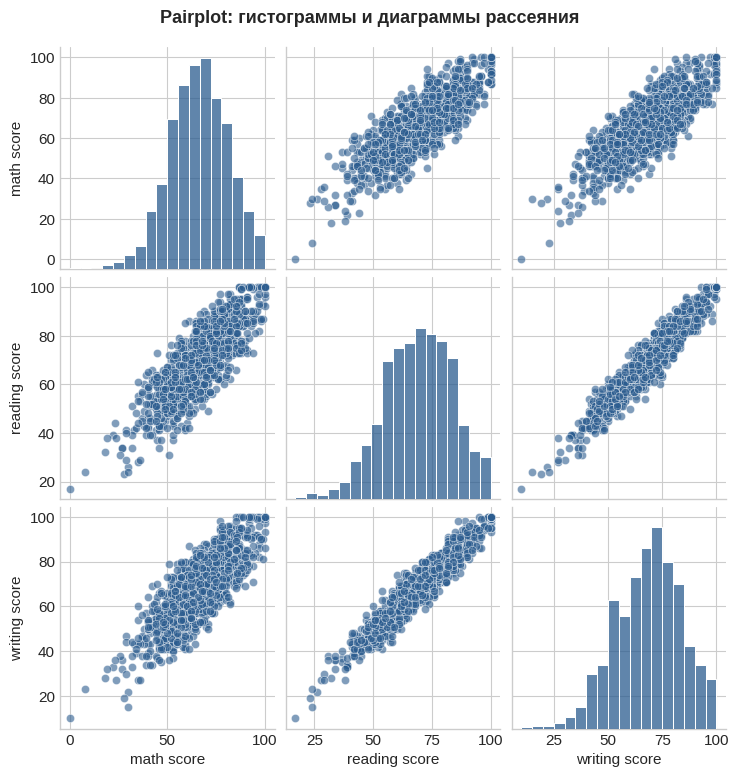

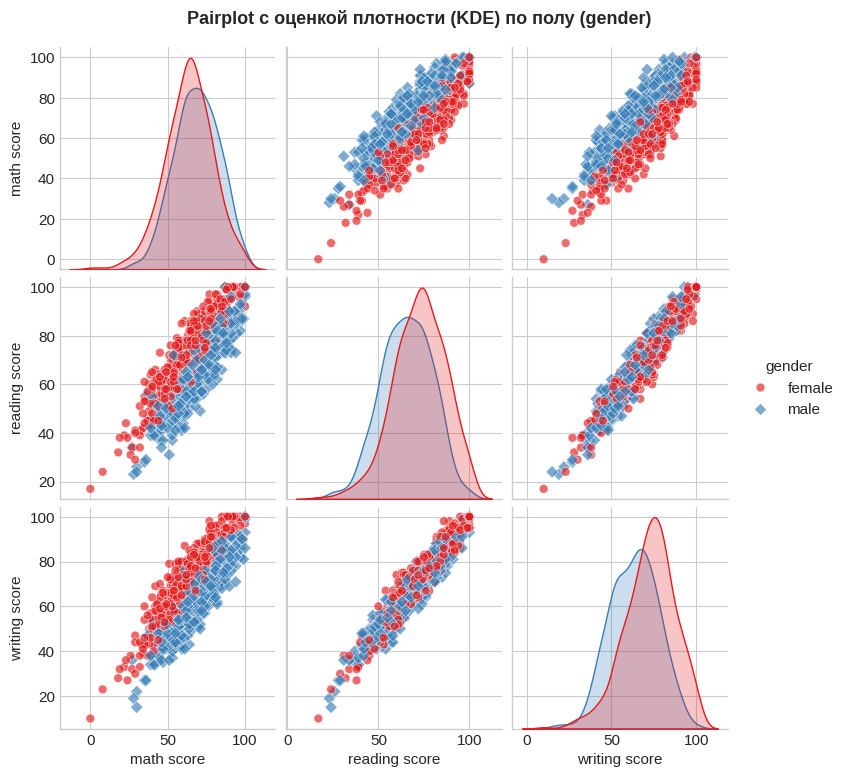

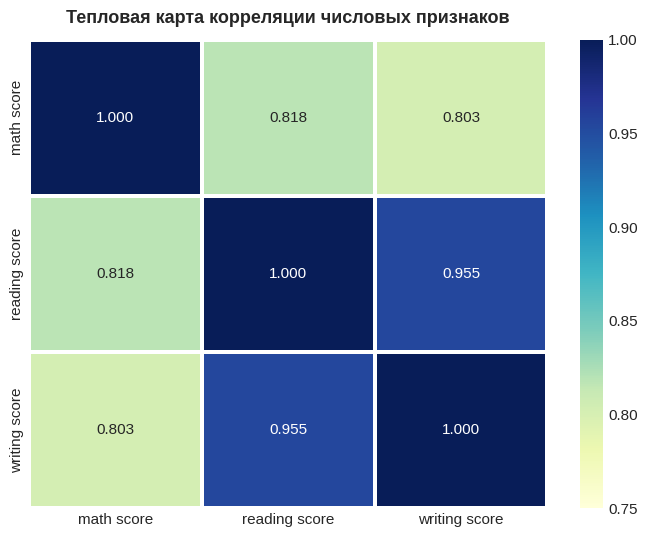

In [8]:
# 3.1 Pairplot с гистограммами
g1 = sns.pairplot(
    df, diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 35, 'edgecolor': 'white', 'color': '#2b5c8f'},
    diag_kws={'bins': 18, 'color': '#2b5c8f', 'edgecolor': 'white'}
)
g1.fig.suptitle('Pairplot: гистограммы и диаграммы рассеяния', y=1.03, fontsize=13, fontweight='bold')
plt.show()

# 3.2 Pairplot с KDE и группировкой по полу (hue='gender')
g2 = sns.pairplot(
    df, hue='gender', diag_kind='kde', palette='Set1',
    markers=['o', 'D'], plot_kws={'alpha': 0.65, 's': 40}
)
g2.fig.suptitle('Pairplot с оценкой плотности (KDE) по полу (gender)', y=1.03, fontsize=13, fontweight='bold')
plt.show()

# 3.3 Тепловая карта для числовых столбцов
fig, ax = plt.subplots(figsize=(7, 5.5))
corr_matrix = df.select_dtypes(include='number').corr()
sns.heatmap(
    corr_matrix, annot=True, fmt='.3f', cmap='YlGnBu',
    vmin=0.75, vmax=1.0, linewidths=1.5, ax=ax
)
ax.set_title('Тепловая карта корреляции числовых признаков', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()